<a href="https://colab.research.google.com/github/SUCCESSneeded/practice/blob/main/Mlmaths.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [125]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [126]:
import random

In [127]:
l=[]
for i in range(10000):
  a=random.randint(1,6)
  b=random.randint(1,6)
  l.append(a+b)

In [128]:
len(l)

10000

In [129]:
l[:5]

[7, 2, 8, 4, 8]

In [130]:
s=(pd.Series(l).value_counts()/pd.Series(l).value_counts().sum()).sort_index()
print(s)

2     0.0302
3     0.0553
4     0.0843
5     0.1123
6     0.1391
7     0.1640
8     0.1387
9     0.1104
10    0.0862
11    0.0539
12    0.0256
Name: count, dtype: float64


<Axes: >

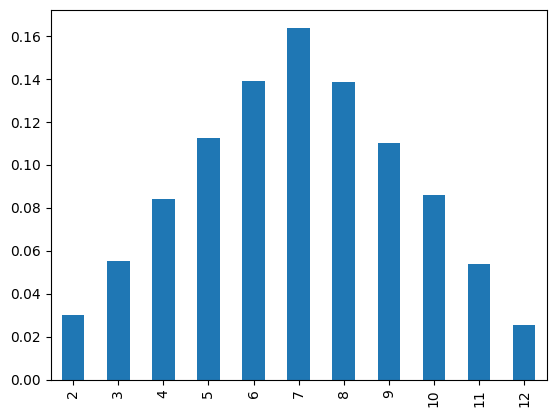

In [131]:
s.plot(kind='bar')

<Axes: >

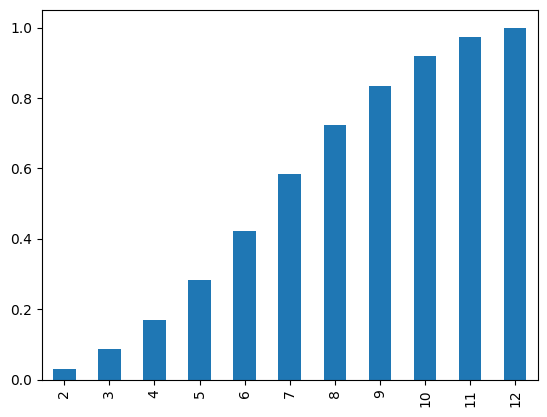

In [132]:
np.cumsum(s).plot(kind='bar')

PARAMETRIC DENSITY ESTIMATION

In [133]:
from numpy.random import normal

sample=normal(loc=50,scale=5,size=1000)
print(sample)
#loc=mean ,scale=std

[44.88606221 54.6414178  55.39342063 43.75009264 46.62230808 46.59720947
 51.29807545 52.53918678 46.44912136 53.4287804  44.50110305 45.25080047
 50.89825164 52.08557081 46.13811046 56.22243328 55.42922399 45.86049141
 47.3262867  57.21999408 52.7535616  46.50424777 47.56715849 49.30650472
 47.40262947 54.32223975 47.87158309 40.04255626 45.61193289 47.23403179
 48.79201651 42.42536463 49.90183858 49.37961095 47.28352183 49.6769116
 52.97228542 52.44013134 50.53653519 44.27380294 48.14951521 41.80735048
 43.65197473 52.2197976  58.52371552 46.08439907 63.76193158 42.40035531
 41.473111   43.46346312 55.34140403 39.75626008 49.92882719 50.38289337
 52.60357551 49.99427392 40.11949164 53.46223808 54.51855925 43.14282545
 48.39921614 55.33953575 52.01646702 56.4746331  42.94527183 46.8360719
 50.25791007 50.21560288 47.31125512 52.88710939 48.84547129 51.71819375
 51.37620884 48.72136822 50.19619717 53.46767958 51.67803428 56.19425846
 51.25896752 48.06772476 42.47013603 41.47508451 59.5

In [134]:
sample.mean()

np.float64(49.857063338900815)

(array([  4.,  21.,  65., 172., 260., 267., 137.,  53.,  18.,   3.]),
 array([32.61536698, 36.11586421, 39.61636144, 43.11685866, 46.61735589,
        50.11785311, 53.61835034, 57.11884756, 60.61934479, 64.11984201,
        67.62033924]),
 <BarContainer object of 10 artists>)

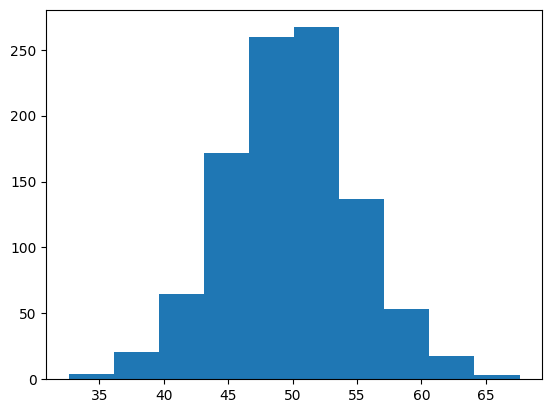

In [135]:
plt.hist(sample,bins=10)

In [136]:
sample_mean=sample.mean()
sample_std=sample.std()

In [137]:
from scipy.stats import norm
dist=norm(sample_mean,sample_std)

In [138]:
sample.min()

np.float64(32.61536698471358)

In [139]:
sample.max()

np.float64(67.6203392398834)

In [140]:
# generating 100 datapts
values=np.linspace(sample.min(),sample.max(),100)

In [141]:
probabilities=[dist.pdf(value) for value in values]

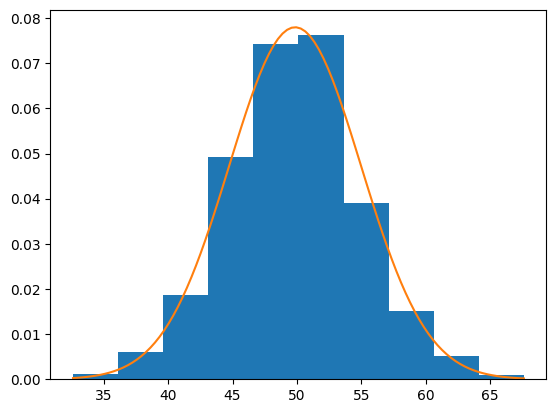

In [142]:
plt.hist(sample,bins=10,density=True)
plt.plot(values,probabilities)

/tmp/ipykernel_3466/1482356190.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(sample)


<Axes: ylabel='Density'>

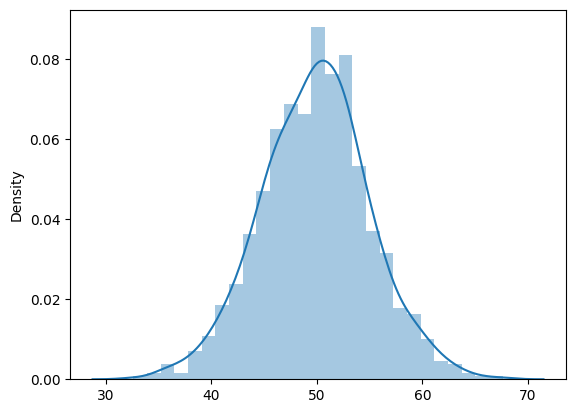

In [143]:
import seaborn as sns
sns.distplot(sample)

KDE

In [144]:
sample1=normal(loc=20,scale=5,size=300)
sample2=normal(loc=40,scale=5,size=700)
sample=np.hstack((sample1,sample2))

In [145]:
sample

array([20.81309883, 16.89145077, 31.55687702, 28.61793785, 15.26116211,
       27.23259709, 29.49461435, 28.59511708, 12.93704147, 16.78374522,
       17.42230919, 18.48223328, 19.51528251, 21.68228781, 19.75614955,
       16.56673246, 16.23467531, 23.41195044, 14.27683866, 17.91850455,
       20.60282558, 18.16632004, 19.18466943, 24.05390404, 25.99549614,
       25.09723075, 27.44763144, 26.17021683, 24.46678343, 24.41321542,
       29.91734285, 11.89593097, 15.0946048 , 22.21843453, 16.16219359,
       22.36340219, 22.56265498, 23.76785595, 25.31306973, 11.25868682,
       23.81299686, 16.02345219, 17.36326277, 17.21465138, 26.20405355,
       25.66227556, 18.31046847, 26.49404509, 16.86225712, 19.99617641,
       19.31748036, 15.11337955, 10.21035411, 18.06851312, 20.38455604,
       30.61663899, 21.24174671, 27.20811315, 17.4379756 , 15.90017643,
       23.09308009, 19.5298424 , 13.37828502, 23.11249467, 24.73160573,
       21.42604785, 23.05041354, 22.17442967, 24.80712292, 26.97

(array([ 2.,  0.,  5.,  1.,  3.,  4.,  6., 11.,  9., 12., 16., 24., 20.,
        25., 19., 18., 19., 22., 27., 16., 12., 14.,  8.,  8., 11.,  6.,
        14., 11., 20., 30., 39., 45., 40., 60., 47., 67., 52., 38., 62.,
        35., 38., 22., 21., 17.,  7.,  3.,  6.,  4.,  3.,  1.]),
 array([ 5.58936696,  6.57175613,  7.5541453 ,  8.53653446,  9.51892363,
        10.5013128 , 11.48370196, 12.46609113, 13.4484803 , 14.43086946,
        15.41325863, 16.3956478 , 17.37803697, 18.36042613, 19.3428153 ,
        20.32520447, 21.30759363, 22.2899828 , 23.27237197, 24.25476113,
        25.2371503 , 26.21953947, 27.20192863, 28.1843178 , 29.16670697,
        30.14909613, 31.1314853 , 32.11387447, 33.09626363, 34.0786528 ,
        35.06104197, 36.04343113, 37.0258203 , 38.00820947, 38.99059863,
        39.9729878 , 40.95537697, 41.93776613, 42.9201553 , 43.90254447,
        44.88493363, 45.8673228 , 46.84971197, 47.83210113, 48.8144903 ,
        49.79687947, 50.77926863, 51.7616578 , 52.74404697,

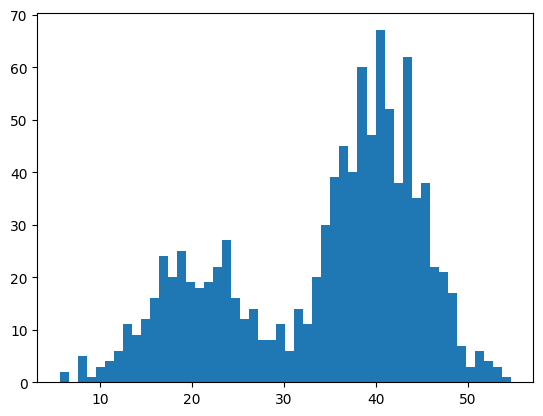

In [146]:
plt.hist(sample,bins=50)

In [147]:
from sklearn.neighbors import KernelDensity

model=KernelDensity(kernel='gaussian',bandwidth=3)
#model.fit(sample)

How to use PDF in data science

In [148]:
dataset=sns.load_dataset("iris")

In [149]:
dataset.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


<Axes: xlabel='sepal_length', ylabel='Density'>

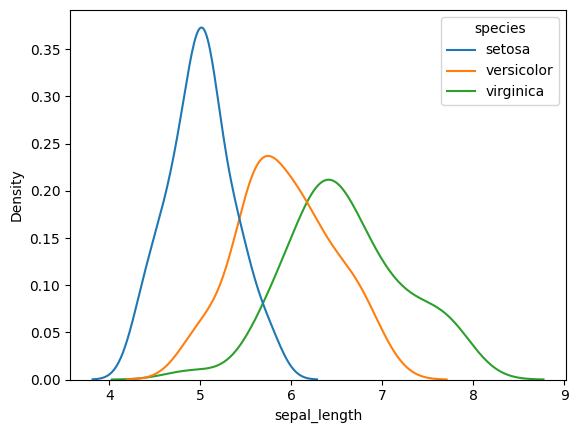

In [150]:
sns.kdeplot(data=dataset,x="sepal_length",hue=dataset["species"])

<Axes: xlabel='sepal_width', ylabel='Density'>

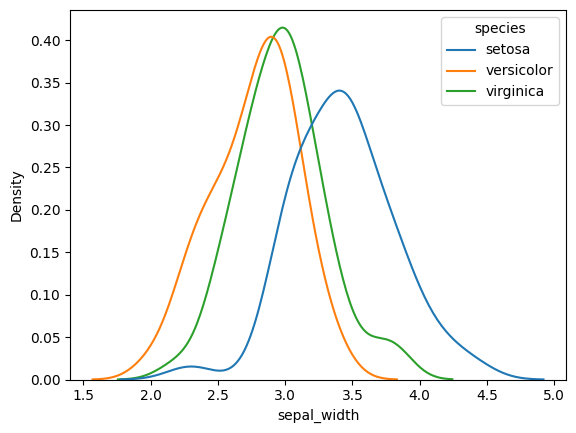

In [151]:
sns.kdeplot(data=dataset,x="sepal_width",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

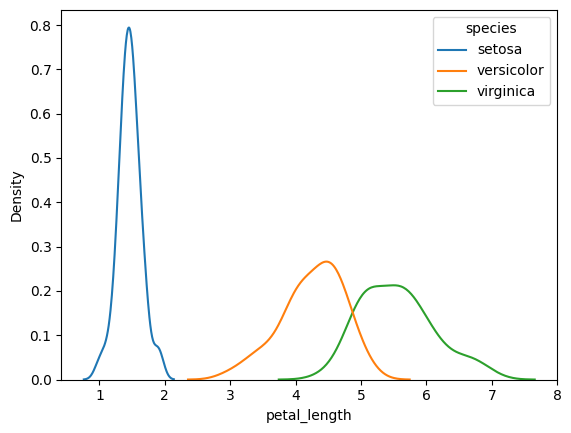

In [152]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

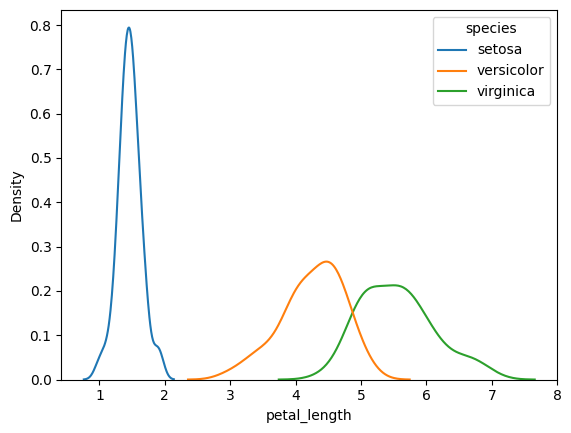

In [153]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

In [154]:
tips=sns.load_dataset("tips")

In [155]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<Axes: xlabel='tip', ylabel='Density'>

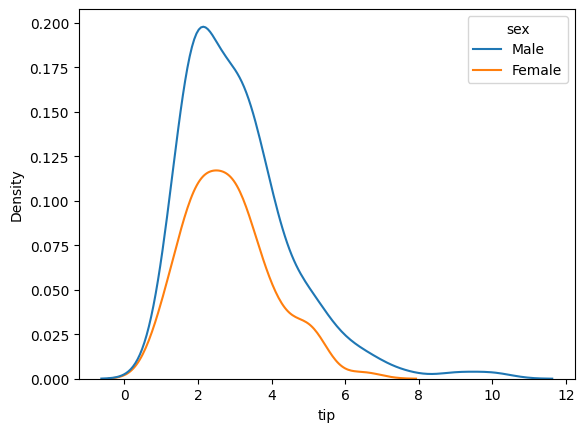

In [156]:
sns.kdeplot(data=tips,x="tip",hue="sex")

<Axes: xlabel='petal_width', ylabel='Density'>

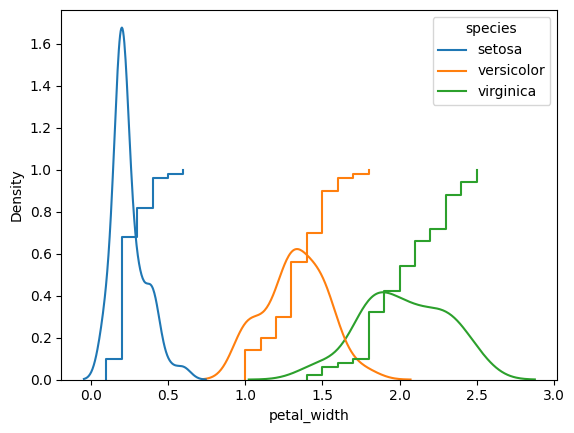

In [157]:
sns.kdeplot(data=dataset,x="petal_width",hue=dataset["species"])
sns.ecdfplot(data=dataset,x="petal_width",hue=dataset["species"])

2D density plots

In [158]:
#contour plots

How to find distribution is normal or not?

In [159]:
iris=sns.load_dataset("iris")

<Axes: xlabel='sepal_length', ylabel='Density'>

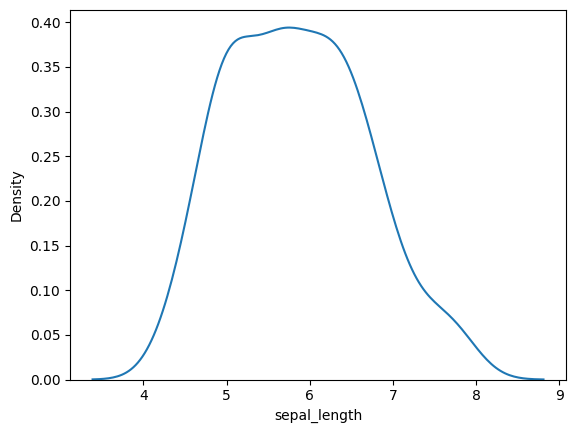

In [160]:
sns.kdeplot(iris["sepal_length"])

In [161]:
temp=sorted(iris['sepal_length'].tolist())

In [162]:
y_quant=[]

for i in range(1,101):
  y_quant.append(np.percentile(temp,i))

In [163]:
samples=np.random.normal(loc=0,scale=1,size=1000)

In [164]:
x_quant=[]

for i in range(1,101):
  x_quant.append(np.percentile(samples,i))

<Axes: >

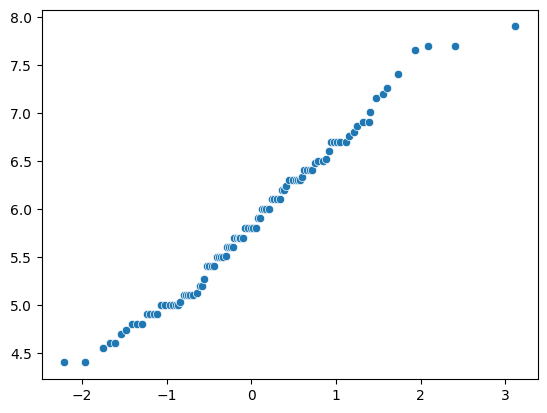

In [165]:
sns.scatterplot(x=x_quant,y=y_quant)

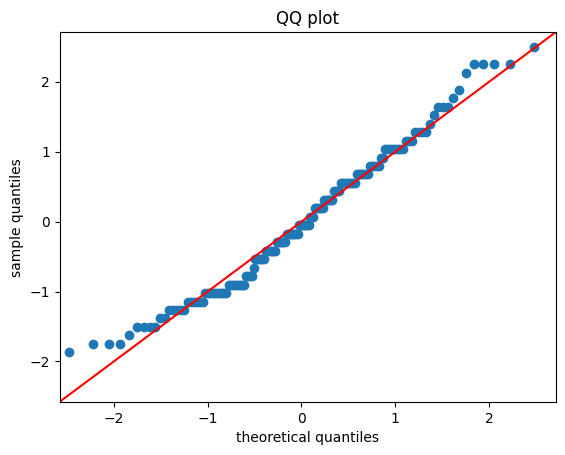

In [166]:
#using statsmodel

import statsmodels.api as sm

#create QQplot of two sets of data
fig=sm.qqplot(iris['sepal_length'],line='45',fit=True)

plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()

In [167]:
import scipy.stats as stats

In [168]:
#genertate a set of random data
x=np.random.uniform(low=0,high=1,size=1000)

(array([116., 100., 113., 109., 104.,  99.,  84.,  75.,  93., 107.]),
 array([1.00417467e-04, 1.00064592e-01, 2.00028767e-01, 2.99992942e-01,
        3.99957116e-01, 4.99921291e-01, 5.99885466e-01, 6.99849641e-01,
        7.99813815e-01, 8.99777990e-01, 9.99742165e-01]),
 <BarContainer object of 10 artists>)

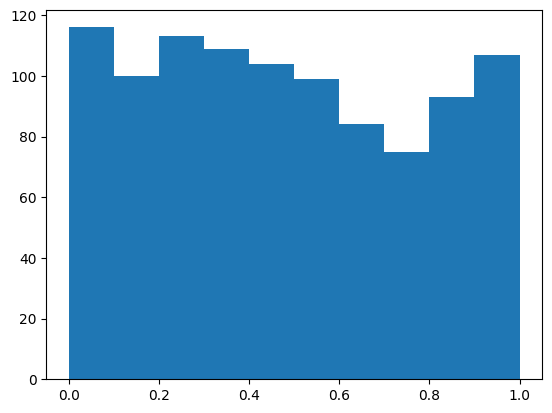

In [169]:
plt.hist(x)

PARETO DISTRIBUTION

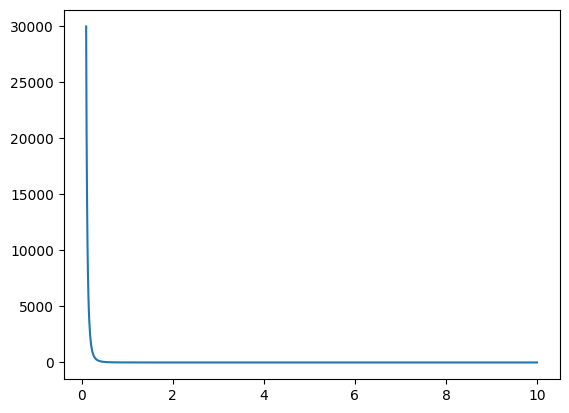

In [170]:
# DEFINE PARAMETERS OF Pareto distribution

alpha=3
xm=1

# create an array of x variables
x=np.linspace(0.1,10,1000)

#calculate teh y values of the pareto distribution
y=alpha*(xm**alpha)/(x**(alpha+1))

plt.plot(x,y)

Text(0.5, 1.0, 'Pareto distribution')

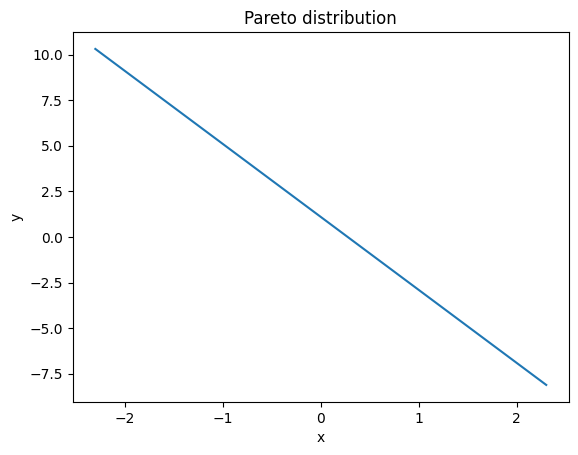

In [171]:
#calculate the log-log plot
plt.plot(np.log(x),np.log(y))
plt.xlabel("x")
plt.ylabel("y")
plt.title("Pareto distribution")

In [172]:
alpha =2
xm=1

x=stats.pareto.rvs(b=alpha,scale=xm,size=1000)

(array([966.,  26.,   3.,   2.,   2.,   0.,   0.,   0.,   0.,   1.]),
 array([ 1.00006845,  5.24201078,  9.48395311, 13.72589545, 17.96783778,
        22.20978012, 26.45172245, 30.69366478, 34.93560712, 39.17754945,
        43.41949178]),
 <BarContainer object of 10 artists>)

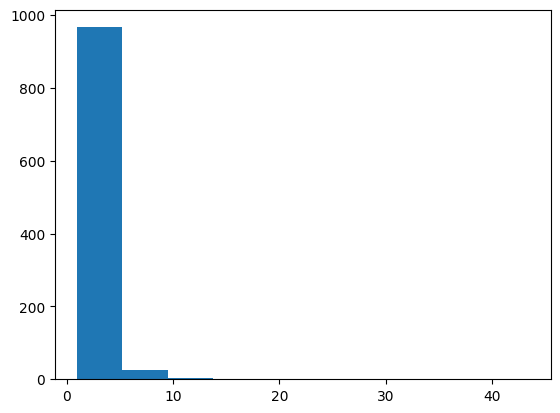

In [173]:
plt.hist(x)

In [174]:
params=stats.pareto.fit(x,floc=0)

#create a pareto distribution object with the fitted parameters
dist=stats.pareto(b=params[0],scale=params[2])

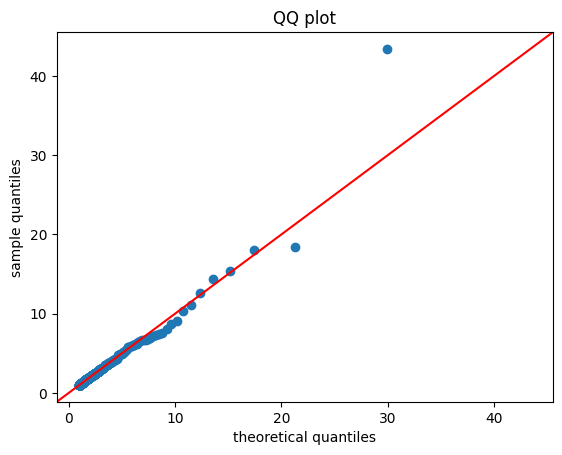

In [175]:
fig=sm.qqplot(x,line='45',dist=dist)
plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()

In [176]:
url="https://raw.githubusercontent.com/SUCCESSneeded/numpy-100/refs/heads/master/battery_health_dataset.csv"
df=pd.read_csv(url,usecols=['Battery Age','Cycle Count','Daily Usage Hours'])

df.head()

,Battery Age,Daily Usage Hours,Cycle Count
0,5,9.797617,1267
1,9,7.101557,1500
2,9,10.085255,1500
3,5,7.946047,1153
4,7,9.628460,1500


In [177]:
df.corr(numeric_only=True)['Battery Age']

,Battery Age
Battery Age,1.000000
Daily Usage Hours,0.058817
Cycle Count,0.952206


In [178]:
from scipy.stats import stats
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [179]:
df.isnull().sum()
# if missing values use df['column'].fillna(df['column'].mean(),inplace=True)

,0
Battery Age,0
Daily Usage Hours,0
Cycle Count,0


In [180]:
x=df.iloc[:,1:4]
y=df.iloc[:,0]

In [181]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2)
'''What does train_test_split() do?
train_test_split() is a function from sklearn.model_selection that divides your dataset into two parts:
- Training data: Used to train the machine-learning model.
- Testing data: Used to check how well the model performs on data it hasn't trained on.

random_state=42 is optional. It makes the random split reproducible, so you get the same split when you run the code again with the same data.'''

"What does train_test_split() do?\ntrain_test_split() is a function from sklearn.model_selection that divides your dataset into two parts:\n- Training data: Used to train the machine-learning model.\n- Testing data: Used to check how well the model performs on data it hasn't trained on.\n\nrandom_state=42 is optional. It makes the random split reproducible, so you get the same split when you run the code again with the same data."

/tmp/ipykernel_3466/1170598051.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['Daily Usage Hours'])


Text(0.5, 1.0, 'Daily Usage Hours QQ plot')

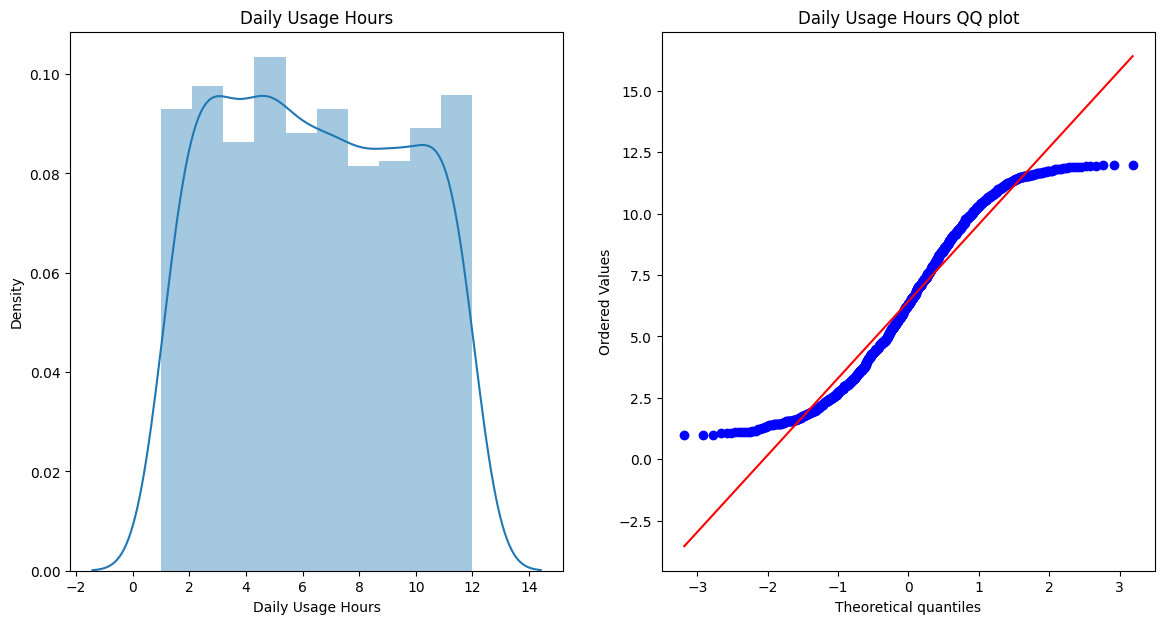

In [182]:
import scipy.stats as stats

plt.figure(figsize=(14,7))
plt.subplot(121)
sns.distplot(x_train['Daily Usage Hours'])
plt.title("Daily Usage Hours")
plt.subplot(122)
stats.probplot(x_train['Daily Usage Hours'],dist="norm",plot=plt)
plt.title("Daily Usage Hours QQ plot")

/tmp/ipykernel_3466/882698.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['Cycle Count'])


Text(0.5, 1.0, 'Cycle Count QQ plot')

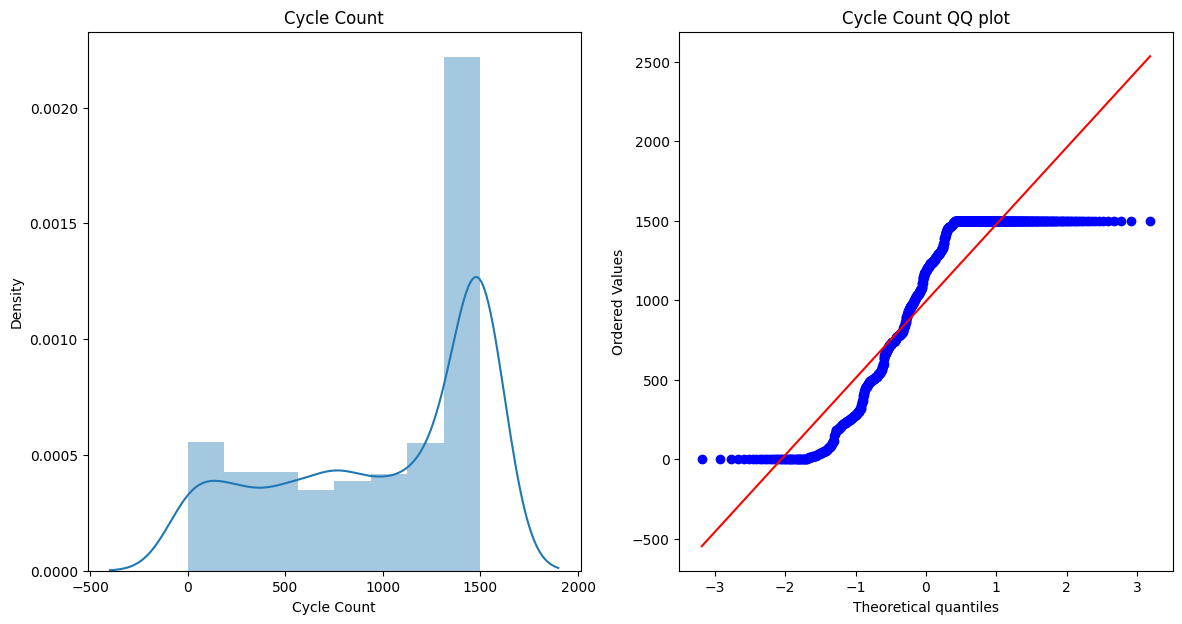

In [183]:
plt.figure(figsize=(14,7))
plt.subplot(121)
sns.distplot(x_train['Cycle Count'])
plt.title("Cycle Count")
plt.subplot(122)
stats.probplot(x_train['Cycle Count'],dist="norm",plot=plt)
plt.title("Cycle Count QQ plot")


In [184]:
clf1=LogisticRegression()
clf2=DecisionTreeClassifier()

In [185]:
print(y.value_counts())
print(x.shape, y.shape)

Battery Age
5    145
3    134
9    130
7    126
6    123
0    113
2    112
1    109
4    107
8    101
Name: count, dtype: int64
(1200, 2) (1200,)


In [186]:
print(x.head())
print(y.head())
print(x.nunique())

   Daily Usage Hours  Cycle Count
0           9.797617         1267
1           7.101557         1500
2          10.085255         1500
3           7.946047         1153
4           9.628460         1500
0    5
1    9
2    9
3    5
4    7
Name: Battery Age, dtype: int64
Daily Usage Hours    1200
Cycle Count           562
dtype: int64


In [187]:
df.corr(numeric_only=True)['Battery Age']

,Battery Age
Battery Age,1.000000
Daily Usage Hours,0.058817
Cycle Count,0.952206


In [188]:
clf1.fit(x_train,y_train)
clf2.fit(x_train,y_train)

y_pred=clf1.predict(x_test)
y_pred2=clf2.predict(x_test)

print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.325
Accuracy DT 0.6958333333333333


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [189]:
trf=FunctionTransformer(np.log1p)

In [190]:
x_train_transform=trf.fit_transform(x_train)
x_test_transform=trf.transform(x_test)

print(x_train_transform)
print(x_test_transform)

     Daily Usage Hours  Cycle Count
117           1.249154     5.707110
399           0.952482     7.179308
553           2.486496     7.313887
919           2.033236     7.313887
587           1.930561     7.118826
..                 ...          ...
766           2.152775     7.142827
329           2.463869     6.672033
845           2.273042     7.284821
757           1.732840     4.174387
517           1.737423     6.576470

[960 rows x 2 columns]
      Daily Usage Hours  Cycle Count
535            1.968433     6.900731
386            2.299011     6.308098
100            1.383744     6.104793
1109           1.479781     7.313887
624            1.977700     3.912023
...                 ...          ...
660            2.355631     5.609472
281            2.015752     6.633318
39             2.096374     7.313887
169            1.868878     4.644391
702            1.736752     5.252273

[240 rows x 2 columns]


In [191]:
clf=LogisticRegression()
clf2=DecisionTreeClassifier()

clf.fit(x_train_transform,y_train)
clf2.fit(x_train_transform,y_train)

y_pred=clf.predict(x_test_transform)
y_pred2=clf2.predict(x_test_transform)

print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.49583333333333335
Accuracy DT 0.6916666666666667


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
